In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

print("Library berhasil diimport!")

Library berhasil diimport!


In [2]:
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset berhasil dibaca!")
print("Ukuran dataset:", df.shape)

display(df.head())

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv
Dataset berhasil dibaca!
Ukuran dataset: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
print("Informasi Dataset:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistik Dataset:")
display(df.describe())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Missing Values:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64

Statistik Dataset:


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


In [4]:
# Menggunakan seluruh fitur clustering yang relevan
features = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]

X = df[features].copy()

# Mengatasi missing values jika ada
X = X.fillna(X.median())

print("Fitur yang digunakan:")
display(X.head())

print("Jumlah fitur:", X.shape[1])

Fitur yang digunakan:


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3


Jumlah fitur: 5


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardisasi berhasil!")
print("Dimensi data:", X_scaled.shape)

Standardisasi berhasil!
Dimensi data: (660, 5)


In [6]:
model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

labels = model.fit_predict(X_scaled)

# Menambahkan hasil cluster ke dataset
df['Cluster'] = labels

print("Clustering berhasil!")
print("\nDistribusi Cluster:")
print(df['Cluster'].value_counts().sort_index())

Clustering berhasil!

Distribusi Cluster:
Cluster
0    385
1    225
2     50
Name: count, dtype: int64


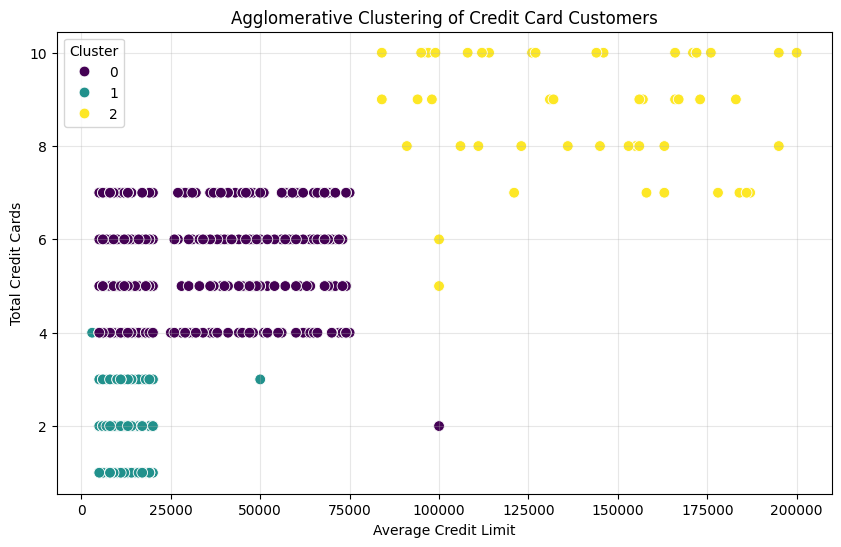

In [7]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster',
    palette='viridis',
    s=60
)

plt.title('Agglomerative Clustering of Credit Card Customers')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)

plt.show()

In [8]:
sil_score = silhouette_score(
    X_scaled,
    labels
)

print("Silhouette Score:", round(sil_score, 6))

Silhouette Score: 0.514764


In [9]:
dbi_score = davies_bouldin_score(
    X_scaled,
    labels
)

print("Davies-Bouldin Index:", round(dbi_score, 6))

Davies-Bouldin Index: 0.68096


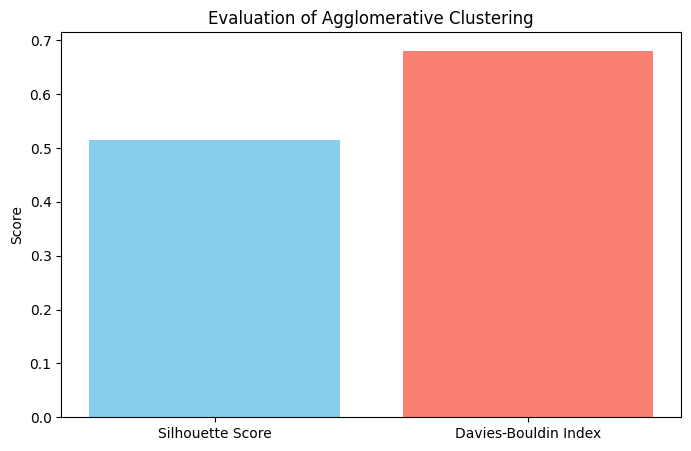

In [10]:
scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

plt.figure(figsize=(8, 5))

plt.bar(
    scores.keys(),
    scores.values(),
    color=['skyblue', 'salmon']
)

plt.title("Evaluation of Agglomerative Clustering")
plt.ylabel("Score")
plt.show()